In [2]:
import numpy as np
import matplotlib.pyplot as plt

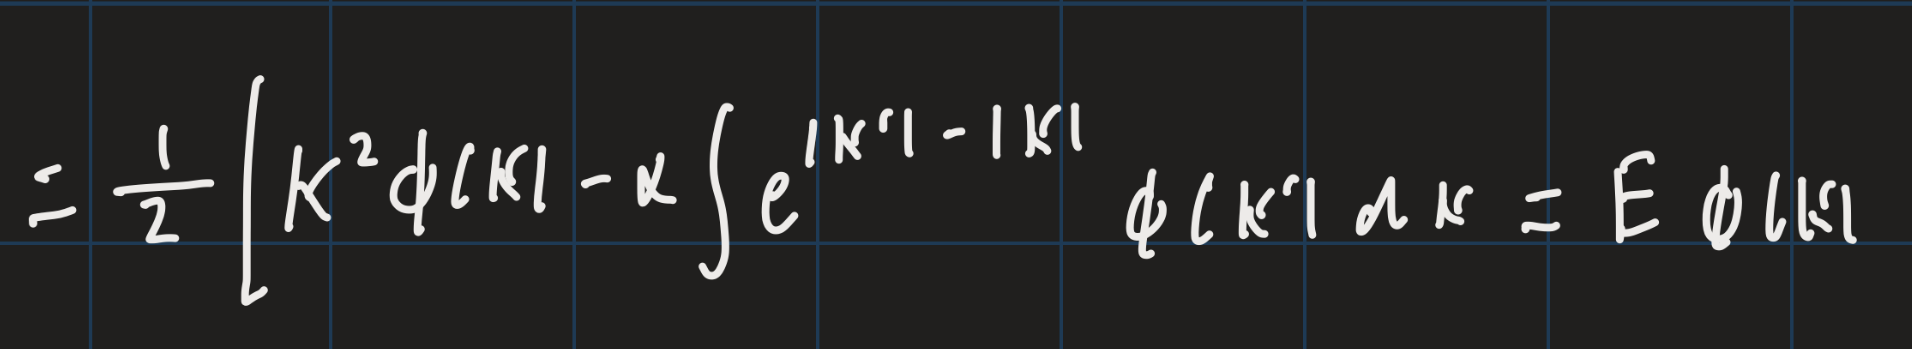
Hvor antaget at hbar og m er 1, skal nu diskretiseres
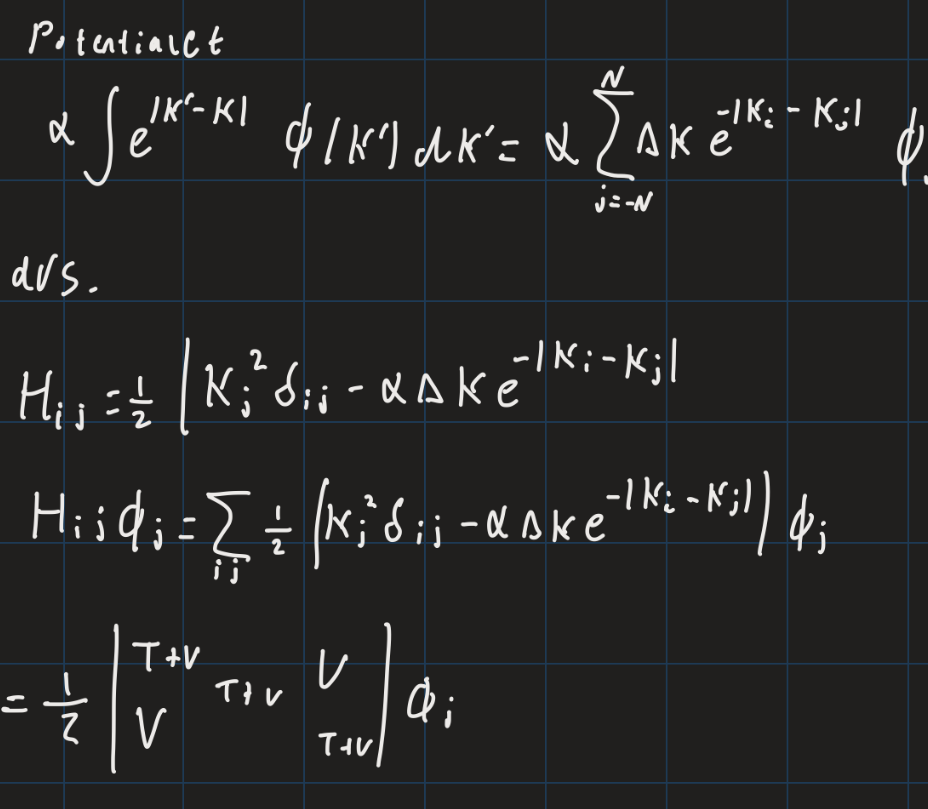

In [3]:
def k_1d(k_max, N0):
    dk=k_max/N0 # skrittstørrelse
    k=np.linspace(-k_max, k_max, 2*N0+1) # k-rummet der går fra -k_max til k_max med 2*N0+1 punkter
    return k, dk

def kinetic_energy(k):
    return np.diag(0.5*k**2) # kinetisk energi 1/2 k^2

def potential(k,a):
    return -0.5*a*dk*np.exp(-np.abs(k[:,None]-k[None,:])) # potentielle energi 1/2*a*e^(-|k1-k2|)

Den diagonaliserer nu T så jeg får en diagonal matrix med de diskretiserede værdier af T som er 1/2 k^2. Til potentialet brugerjeg np.abs(k[:,None]-k[None,:]) det første er række det andet er søjle, så det ene bliver en rækkevektor og det andet en søjlevektor, så får jeg en matrix med alle kombinationer af k1-k2.

In [4]:
k, dk = k_1d(35, 2000) # 
a=1000
V=potential(k, a) # potentialet er en matrix med elementer V_ij = 0.5*exp(|k_i-k_j|)
T=kinetic_energy(k) # T er en diagonal matrix med elementer T_ii = 0.5*k_i^2
H=T+V # H er Hamilton operatoren, som er summen af T og V
print("Hamiltonian matrix H:\n", H)

Hamiltonian matrix H:
 [[ 6.03750000e+02 -8.59820706e+00 -8.44904739e+00 ... -3.60242234e-30
  -3.53992836e-30 -3.47851852e-30]
 [-8.59820706e+00  6.03137653e+02 -8.59820706e+00 ... -3.66601958e-30
  -3.60242234e-30 -3.53992836e-30]
 [-8.44904739e+00 -8.59820706e+00  6.02525613e+02 ... -3.73073957e-30
  -3.66601958e-30 -3.60242234e-30]
 ...
 [-3.60242234e-30 -3.66601958e-30 -3.73073957e-30 ...  6.02525613e+02
  -8.59820706e+00 -8.44904739e+00]
 [-3.53992836e-30 -3.60242234e-30 -3.66601958e-30 ... -8.59820706e+00
   6.03137653e+02 -8.59820706e+00]
 [-3.47851852e-30 -3.53992836e-30 -3.60242234e-30 ... -8.44904739e+00
  -8.59820706e+00  6.03750000e+02]]


Den passer, så nu har jeg skrevet min hamilton operator H som en matrice. 

In [5]:
E,U=np.linalg.eigh(H)

In [6]:
E_min = np.min(E)
print("Minimum eigenvalue E_min:", E_min)

Minimum eigenvalue E_min: -978.0336773519914


np.linalg.eig(f) giver de egenværdier og egenvektorer for matrix f
og det passer med maple.
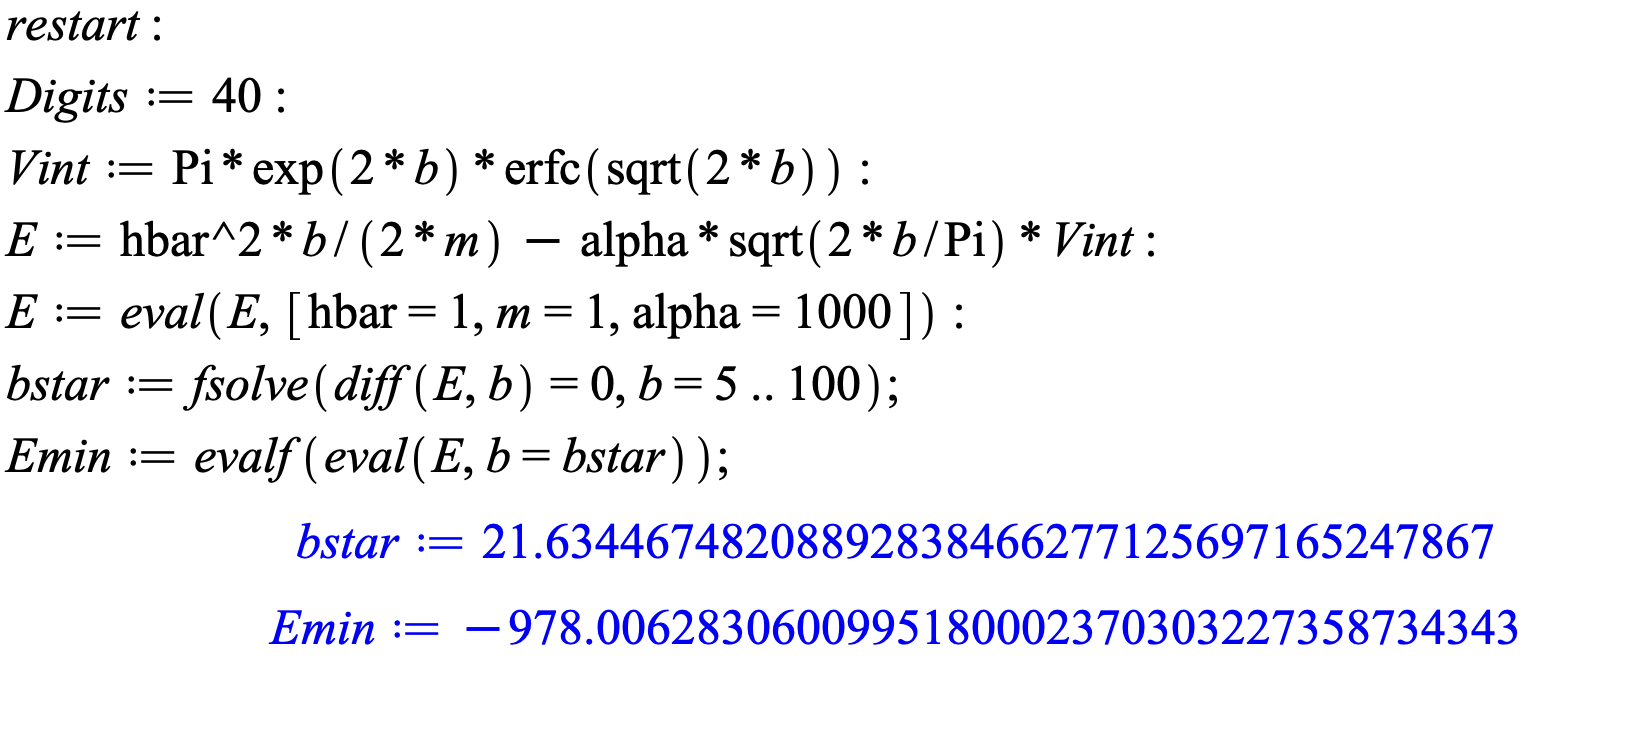

Dvs. med diagonaliseringmetoden som kan give mig den eksakteværdi for stor nok N bliver 
E_min=-978,060 og med variationsregning fik jeg at den var E_minv-978,006
E_min<E_minv, så det passer med at variationsmetoden giver en øvre grænse for E_min.>  
claude regnede på det og fik at den rigtige værdi for E_min var -978,01. passer med det jeg får for N=2000

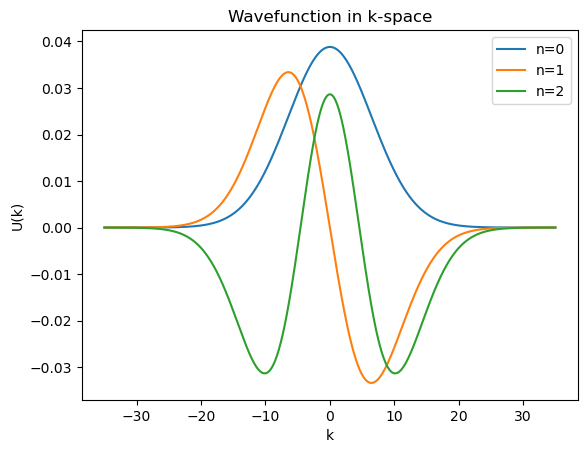

In [7]:
plt.plot(k,U[:,0],label="n=0")
plt.plot(k,U[:,1],label="n=1")
plt.plot(k,U[:,2],label="n=2")
plt.xlabel("k")
plt.ylabel("U(k)")
plt.legend()
plt.title("Wavefunction in k-space")
plt.show()

Hvis jeg vil have den tilbage i x-rummet bruger jeg invers fourier transformering
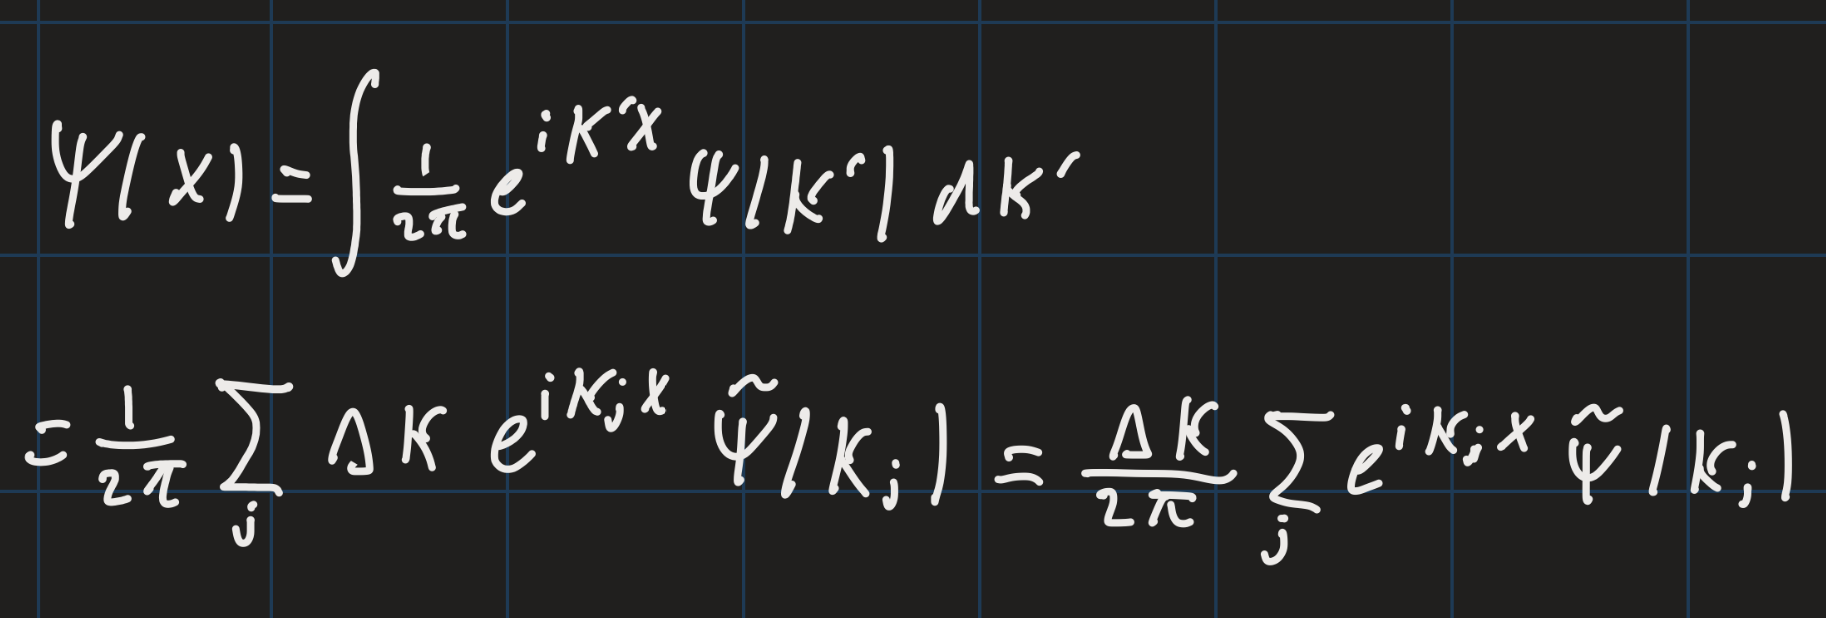

In [8]:
x=np.linspace(-1, 1, 4001) # x-rummet der går fra -1 til 1 med 4001 punkter
M = np.exp(1j * x[:, None] * k[None, :])    # (4001, 20001)
U_x = dk/(2*np.pi) * (M @ U)                # (4001, 2001) # @ er matrix multiplikation, så jeg får U_x som er U i x-rummet

n=0: 1.0
n=1: 0.9999999999999998
n=2: 0.9999999999999999


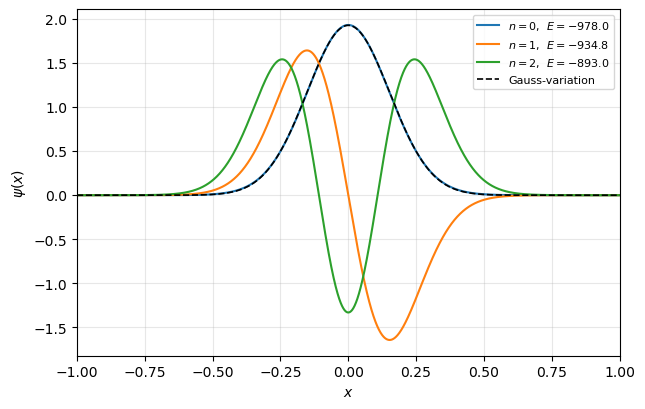

In [9]:
b_star = 21.63446748

fig, ax = plt.subplots(figsize=(7, 4.5))

for n in range(3):
    psi = U_x[:, n] # henter den n-te kolonne af U_x, som er bølgefunktionen i x-rummet for den n-te energitilstand
    psi = psi * np.exp(-1j*np.angle(psi[np.argmax(np.abs(psi))])) # fjerner den komplekse fase, så bølgefunktionen er reel
    psi = psi.real #fjerner den imaginære del, så bølgefunktionen er reel
    psi = psi / np.sqrt(np.trapezoid(psi**2, x)) # normaliserer bølgefunktionen, så integralet af psi^2 er 1
    print(f"n={n}: {np.trapezoid(psi**2, x)}")   # skal give 1.0
    if psi[np.argmax(np.abs(psi))] < 0: # hvis bølgefunktionen er negativ ved dens maksimum, så vender jeg den om, så den er positiv ved maksimum
        psi = -psi
    ax.plot(x, psi, label=f"$n={n}$,  $E={E[n]:.1f}$") #plotter bølgefunktionen i x-rummet for den n-te energitilstand

ax.plot(x, (2*b_star/np.pi)**0.25 * np.exp(-b_star*x**2), #plotter variations regnings funktionen og ser de matcher med den numeriske løsning
        "k--", lw=1.2, label="Gauss-variation")

ax.set_xlim(-1, 1); ax.set_xlabel("$x$"); ax.set_ylabel(r"$\psi(x)$")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.show()

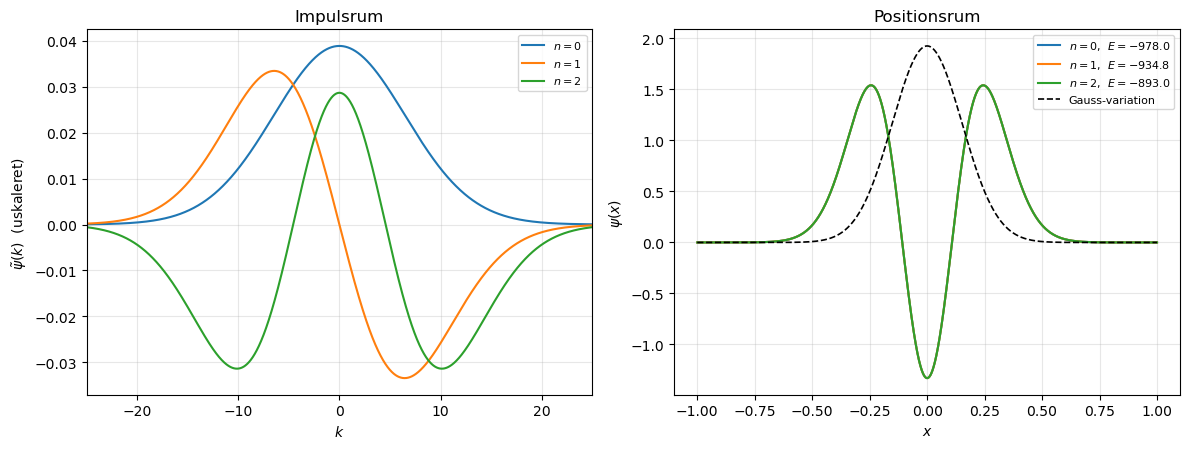

In [10]:
n_vis = 3

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))

for n in range(n_vis):
    # --- k-rum: egenvektoren er psi-tilde direkte
    ax[0].plot(k, U[:, n], label=f"$n={n}$") # U[:, n] er egenvektoren i k-rum for den n-te tilstand så U er en matrix med kolonner som er egenvektorerne i k-rum

    # --- x-rum: psi(x) = sum_a psi-tilde(k_a) exp(i k_a x)
    ax[1].plot(x, psi, label=f"$n={n}$,  $E={E[n]:.1f}$")

# sammenlign grundtilstanden med Gauss-ansatsen
b_star = 21.63446748
ax[1].plot(x, (2*b_star/np.pi)**0.25 * np.exp(-b_star*x**2),
           "k--", lw=1.2, label="Gauss-variation")

ax[0].set_xlim(-25, 25); ax[0].set_xlabel("$k$")
ax[0].set_ylabel(r"$\tilde\psi(k)$  (uskaleret)")
ax[0].set_title("Impulsrum"); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)

ax[1].set_xlabel("$x$"); ax[1].set_ylabel(r"$\psi(x)$")
ax[1].set_title("Positionsrum"); ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)

fig.tight_layout(); plt.show()

In [11]:
print(np.trapezoid(U[:,0]**2 / dk, k))
print(np.linalg.norm(U[:,0]))
print(dk)

0.9999999999999913
1.0000000000000007
0.0175


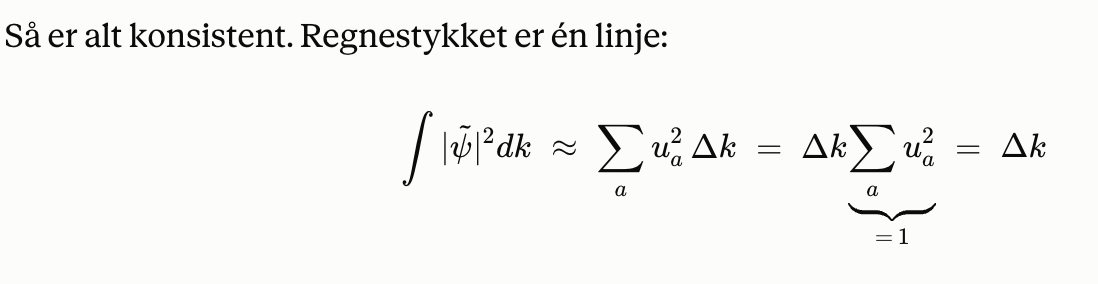

In [12]:
print(dk)

0.0175
